# 5. Readout: from atoms to a molecule

**What you will learn:** how a variable-length bag of atom vectors becomes one
fixed-length molecular vector, why that choice is not cosmetic, and why
molecular GNNs usually sum.

After message passing you hold `[n_atoms, hidden]`. Toxicity is one number per
*molecule*. Something has to collapse the atom axis, and whatever it is must
be **permutation invariant** — atoms have no canonical order, so a readout
that depends on ordering would give two answers for the same molecule.

Three standard choices:

| readout | formula | behaviour with molecular size |
|---|---|---|
| mean | $\frac{1}{n}\sum_i h_i$ | **intensive** — invariant to size |
| sum | $\sum_i h_i$ | **extensive** — scales with size |
| attention | $\sum_i \alpha_i (W h_i)$, $\alpha$ a learned softmax | learned; can focus on a substructure |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from mgnn import features as F
from mgnn.data import WORKED_TASKS, load_tox21_graphs
from mgnn.models import MolecularGNN
from mgnn.pooling import AttentionPooling, global_mean_pool, global_sum_pool
from mgnn.splits import scaffold_split
from mgnn.train import collate_graphs, evaluate, set_seed, train_model

np.set_printoptions(precision=3, suppress=True, linewidth=130)
plt.rcParams["figure.dpi"] = 110
set_seed(0)

## 5.1 First, batching: one big disconnected graph

Molecules have different atom counts, so they cannot be stacked into a tensor.
The standard trick is to concatenate them into a **single graph with several
components**: stack the node features, shift each molecule's `edge_index` by
the number of atoms already placed, and keep a `batch` vector recording which
molecule each atom came from.

Because the components share no edges, message passing cannot leak between
molecules. The readout then has to group by `batch` — which is exactly what
the pooling functions do.

In [2]:
graphs = [F.smiles_to_graph(s) for s in ["CCO", "c1ccccc1", "CC(=O)Nc1ccc(O)cc1"]]
batch = collate_graphs(graphs)

print("molecule atom counts:", [g.num_nodes for g in graphs])
print("batched x:", tuple(batch.x.shape))
print("batch vector:", batch.batch.tolist())
print("edge_index max index:", int(batch.edge_index.max()),
      "< total atoms:", batch.x.shape[0])

src_mol = batch.batch[batch.edge_index[0]]
dst_mol = batch.batch[batch.edge_index[1]]
print("every edge stays inside one molecule:", bool(torch.equal(src_mol, dst_mol)))

molecule atom counts: [3, 6, 11]
batched x: (20, 41)
batch vector: [0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
edge_index max index: 19 < total atoms: 20
every edge stays inside one molecule: True


## 5.2 Sum is extensive, mean is not

The cleanest demonstration: compare a molecule with an exact copy of itself
written as two fragments. Chemically it is "twice as much stuff". With
identical atom representations, sum doubles and mean does not move at all.

In [3]:
mono = F.smiles_to_graph("CCO")
dimer = F.smiles_to_graph("CCO.CCO")
b1, b2 = collate_graphs([mono]), collate_graphs([dimer])
h1 = torch.ones(b1.x.shape[0], 4)
h2 = torch.ones(b2.x.shape[0], 4)

print("monomer (3 atoms)  sum:", global_sum_pool(h1, b1.batch, 1).numpy(),
      " mean:", global_mean_pool(h1, b1.batch, 1).numpy())
print("dimer   (6 atoms)  sum:", global_sum_pool(h2, b2.batch, 1).numpy(),
      " mean:", global_mean_pool(h2, b2.batch, 1).numpy())

monomer (3 atoms)  sum: [[3. 3. 3. 3.]]  mean: [[1. 1. 1. 1.]]
dimer   (6 atoms)  sum: [[6. 6. 6. 6.]]  mean: [[1. 1. 1. 1.]]


### Why extensivity is usually what you want

Many molecular properties are **additive over atoms or fragments**:

* molar mass, exactly;
* lipophilicity, approximately — the classic cLogP methods are literally sums
  of atomic or fragmental contributions;
* the *count* of toxicophores or reactive groups, which is often what an assay
  like SR-MMP responds to.

A mean readout has to express "this molecule contains two nitro groups" as a
*proportion* of nitro-ness, which it then cannot distinguish from a smaller
molecule with one nitro group. For a dose-driven endpoint that is the wrong
invariance.

Mean is the right choice when the property really is intensive — a per-atom
average, a normalised score — or when your training set has a wide size
distribution and you are worried about the sum's scale.

Here is the size-dependence made visible across a homologous series.

,atoms,sum readout,mean readout
smiles,,,
C,1,1.0,1.0
CC,2,2.0,1.0
CCC,3,3.0,1.0
CCCC,4,4.0,1.0
CCCCC,5,5.0,1.0
CCCCCC,6,6.0,1.0
CCCCCCC,7,7.0,1.0
CCCCCCCC,8,8.0,1.0


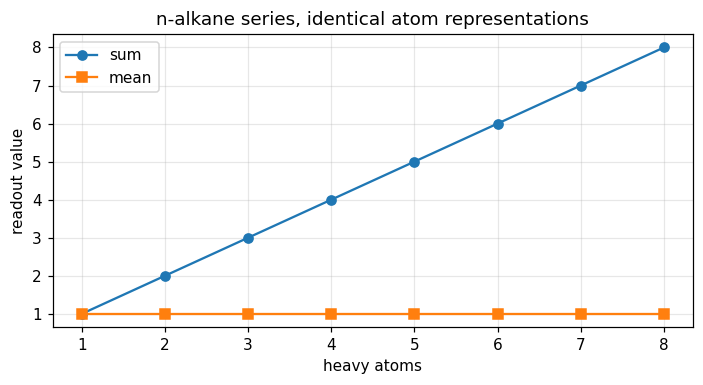

In [4]:
series = ["C", "CC", "CCC", "CCCC", "CCCCC", "CCCCCC", "CCCCCCC", "CCCCCCCC"]
rows = []
for smi in series:
    g = F.smiles_to_graph(smi)
    b = collate_graphs([g])
    h = torch.ones(b.x.shape[0], 1)
    rows.append({"smiles": smi, "atoms": g.num_nodes,
                 "sum readout": float(global_sum_pool(h, b.batch, 1)),
                 "mean readout": float(global_mean_pool(h, b.batch, 1))})
alkanes = pd.DataFrame(rows).set_index("smiles")
display(alkanes)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(alkanes["atoms"], alkanes["sum readout"], marker="o", label="sum")
ax.plot(alkanes["atoms"], alkanes["mean readout"], marker="s", label="mean")
ax.set_xlabel("heavy atoms"); ax.set_ylabel("readout value")
ax.set_title("n-alkane series, identical atom representations")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 5.3 Attention pooling: a learned weighted sum

$$ z = \sum_i \alpha_i (W h_i), \qquad
   \alpha = \mathrm{softmax}_{i \in \text{molecule}}(w^\top h_i) $$

The right inductive bias when **one substructure drives the label** — a single
nitroaromatic, a Michael acceptor, a reactive epoxide — because a sum over
fifty atoms dilutes a signal carried by three of them. It also hands you a
per-atom weight you can draw on the structure (notebook 08).

The subtlety: **the softmax must run within each molecule, never across the
batch.** Get that wrong and a molecule's prediction depends on which other
molecules happened to share its batch — a bug that trains fine, validates
fine, and gives different answers at inference time. The test below is the one
that catches it; `tests/test_pooling.py` runs it in CI.

In [5]:
pool = AttentionPooling(F.ATOM_FEATURE_DIM, 8)
pool.eval()

big = collate_graphs(graphs)
alone = collate_graphs([graphs[2]])
with torch.no_grad():
    pooled_big, alpha = pool(big.x, big.batch, big.n_graphs, return_weights=True)
    pooled_alone = pool(alone.x, alone.batch, 1)

for k in range(big.n_graphs):
    print(f"  molecule {k} ({graphs[k].smiles:<20s}) attention sums to "
          f"{float(alpha[big.batch == k].sum()):.6f}")
print("\nsame answer in a batch and alone:",
      bool(torch.allclose(pooled_alone[0], pooled_big[2], atol=1e-6)))

  molecule 0 (CCO                 ) attention sums to 1.000000
  molecule 1 (c1ccccc1            ) attention sums to 1.000000
  molecule 2 (CC(=O)Nc1ccc(O)cc1  ) attention sums to 1.000000

same answer in a batch and alone: True


## 5.4 Does it matter on real data?

Three identical GIN models on the same scaffold split of Tox21, differing only
in readout. Short training on a subset, one seed — again a smoke test rather
than a benchmark, and the differences below are well within the noise of a
single run. What it does establish is that all three train, and it gives you
the code to run the comparison properly.

In [6]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=False)
train_idx, valid_idx, _test_idx = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
d_train, d_valid = ds.subset(train_idx[:2500]), ds.subset(valid_idx)
print(f"{len(d_train)} training molecules, {len(d_valid)} validation molecules")

rows = []
for pooling in ["sum", "mean", "attention"]:
    set_seed(0)
    model = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind="gin",
                         pooling=pooling, dropout=0.1)
    train_model(model, d_train.graphs, d_valid.graphs, WORKED_TASKS, epochs=10,
                batch_size=64, lr=1e-3, pos_weight=torch.tensor([5.0, 3.0]),
                verbose=False, early_stopping_patience=None)
    m = evaluate(model, d_valid.graphs, WORKED_TASKS)
    rows.append({"readout": pooling, "parameters": model.n_parameters(),
                 "valid ROC-AUC (mean)": m["mean_roc_auc"],
                 "NR-AR": m["per_task"]["NR-AR"]["roc_auc"],
                 "SR-MMP": m["per_task"]["SR-MMP"]["roc_auc"]})
    print(f"  {pooling:<10s} done")

display(pd.DataFrame(rows).set_index("readout").style.format({
    "valid ROC-AUC (mean)": "{:.3f}", "NR-AR": "{:.3f}", "SR-MMP": "{:.3f}"}))

2500 training molecules, 782 validation molecules


  sum        done


  mean       done


  attention  done


,parameters,valid ROC-AUC (mean),NR-AR,SR-MMP
readout,,,,
sum,32325,0.739,0.733,0.744
mean,32325,0.765,0.766,0.765
attention,36550,0.758,0.751,0.765


## 5.5 Readouts you will meet elsewhere

* **max pooling** — "does this molecule contain an atom with property X at
  all". Sharp, and gradient flows to only one atom per feature, which makes it
  train poorly on its own; usually concatenated with sum or mean.
* **concatenate sum ‖ mean ‖ max** — cheap, strictly more informative than any
  one of them, and a sensible default if you do not want to think about it.
* **Set2Set** (Vinyals et al., ICLR 2016, DOI:
  [10.48550/arXiv.1511.06391](https://doi.org/10.48550/arXiv.1511.06391)) — an
  LSTM-based order-invariant readout used in the original MPNN paper for
  quantum-chemistry targets.
* **virtual node** — add one extra node bonded to every atom; after one layer
  it has seen the whole molecule, and you read out *its* state. A shortcut for
  long-range information, closely related to what notebook 09's 1995
  architecture does by connecting everything to everything.

In [7]:
sum_z = global_sum_pool(torch.ones(big.x.shape[0], 4), big.batch, big.n_graphs)
mean_z = global_mean_pool(torch.ones(big.x.shape[0], 4), big.batch, big.n_graphs)
concat = torch.cat([sum_z, mean_z], dim=1)
print("sum ‖ mean concatenation:", tuple(concat.shape),
      "-- twice the width, both invariances available to the head")

sum ‖ mean concatenation: (3, 8) -- twice the width, both invariances available to the head


## What to take away

* Batching = one disconnected graph plus a `batch` vector; edges never cross
  molecules.
* Sum is extensive, mean is intensive. Most molecular endpoints are closer to
  extensive, which is why sum is the usual default.
* Attention pooling focuses on substructures and yields per-atom weights, but
  its softmax must be scoped to the molecule.
* If in doubt, concatenate sum and mean.

**Next:** notebook 06, oversmoothing — what actually goes wrong when you stack
layers, measured at 2, 4, 8 and 16.